# Task 8 — VaR & ES Backtesting
### QFI Internship · Market Risk Project · Phase 8
**Prepared by:** Arham Shah

---

**Objective.** Put all four VaR models (HS, EWMA, GARCH, GJR) through the standard regulatory battery of tests, on **identical dates**, and measure how much regulatory capital each one would require. We also check how much these tests can and cannot detect with about 1,000 days of data.

**What this notebook delivers**
- **A fair comparison:** every model is tested on the same common sample for each window
- **Kupiec POF**, **Christoffersen independence** and **conditional coverage** for 4 models × 3 windows × 3 confidence levels (36 cells)
- An **Expected Shortfall backtest**: is the average loss on bad days as large as ES predicted?
- The **Basel traffic light over time** and a Basel 2.5-style **capital charge** for each model
- A **power analysis**: how often Kupiec would catch a model that is 2× too optimistic
- Exception-clustering diagnostics, plus exports for Task 9

> **Pipeline:** Task 3 Portfolio → Task 4 HS → Task 5 EWMA → Task 6 GARCH → Task 7 GJR-GARCH → **Task 8 Backtesting** → Task 9 Model selection → Task 10 →

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. What a backtest checks
A 99% VaR is a promise: *losses exceed this on 1% of days, and those days arrive at random.* Each test checks a different part of that promise.

| Test | Checks | H₀ | Statistic |
|---|---|---|---|
| **Kupiec POF** | the exception *rate* | rate = 1 − c | LR_uc ~ χ²(1) |
| **Christoffersen independence** | exceptions don't *cluster* | P(exc. today \| exc. yesterday) = P(exc. today \| none yesterday) | LR_ind ~ χ²(1) |
| **Conditional coverage** | rate **and** independence together | both | LR_cc = LR_uc + LR_ind ~ χ²(2) |
| **ES test** | *size* of losses beyond VaR | E[loss / ES − 1 \| exception] = 0 | one-sided bootstrap |
| **Basel traffic light** | the supervisory backstop | exceptions in the last 250 days at 99% | 0–4 green · 5–9 yellow · 10+ red |

**Verdict used here.** A cell **passes** if Kupiec, conditional coverage and the ES test all have p > 0.05 and, at 99%, the model is not in the red zone.

**ES test, in plain words.** On each exception day we compare the actual loss with the ES that was forecast. If ES is right, the ratio loss/ES averages 1.
A ratio well above 1 means the model *understates* how bad bad days are, which FRTB treats as the key risk.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the portfolio, the toolkit and every model's forecasts
Forecasts come from the Task 4–7 files. If a file is missing, it is rebuilt with that task's own engine. Each file is checked to be built on the same portfolio.

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


In [5]:
# ---- Shared volatility engine: EWMA (Task 5), GARCH (Task 6), GJR (Task 7) ----
from scipy.optimize import minimize
from scipy.special import gammaln
REFIT_EVERY, MIN_EST, EWMA_SEED = 21, 500, 30

def ewma_sigma(r, lam=EWMA_LAMBDA, seed=EWMA_SEED):
    e2 = np.asarray(r, float) ** 2; h0 = e2[:seed].mean()
    h = np.r_[h0, lfilter([1 - lam], [1, -lam], e2[:-1], zi=[lam * h0])[0]]
    return pd.Series(np.sqrt(h), index=r.index)

def backcast(e, n=75):
    w = 0.94 ** np.arange(min(n, len(e))); w /= w.sum()
    return float(w @ e[:len(w)] ** 2)

def vol_var(e, omega, alpha, beta, gamma=0.0):
    """h_t = omega + (alpha + gamma*1[e_{t-1}<0]) e_{t-1}^2 + beta h_{t-1}.  gamma = 0 -> GARCH(1,1)."""
    h0 = backcast(e)
    u = omega + (alpha + gamma * (e[:-1] < 0)) * e[:-1] ** 2
    return np.r_[h0, lfilter([1.0], [1.0, -beta], u, zi=[beta * h0])[0]]

def nll(p, x, dist, asym):
    mu, omega, alpha, beta = p[:4]
    gamma = p[4] if asym else 0.0
    e = x - mu
    h = np.maximum(vol_var(e, omega, alpha, beta, gamma), 1e-10)
    if dist == 'normal':
        ll = -0.5 * (np.log(2 * np.pi) + np.log(h) + e * e / h)
    else:
        nu = p[-1]
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
              - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(e * e / (h * (nu - 2))))
    return -ll.sum()

def fit_vol(r, dist='normal', asym=False, x0=None):
    """Gaussian or Student-t (Q)MLE of GARCH(1,1) or GJR-GARCH(1,1,1). Returns in percent units internally."""
    x = np.asarray(r, float) * 100
    v = x.var()
    tb = [(2.1, 100)] if dist == 't' else []
    if asym:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.02, 0.88, 0.10] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (0.0, 0.5), (0.0, 0.9999), (0.0, 0.5)] + tb
        con = lambda p: 0.9999 - p[2] - p[3] - 0.5 * p[4]
    else:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.08, 0.88] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (1e-6, 0.5), (0.0, 0.9999)] + tb
        con = lambda p: 0.9999 - p[2] - p[3]
    res = minimize(nll, x0, args=(x, dist, asym), method='SLSQP', bounds=bnds,
                   constraints={'type': 'ineq', 'fun': con}, options={'maxiter': 500, 'ftol': 1e-10})
    p = res.x
    gamma = p[4] if asym else 0.0
    pers = p[2] + p[3] + 0.5 * gamma
    k, ll = len(p), -res.fun
    return {'dist': dist, 'asym': asym, 'mu': p[0] / 100, 'omega': p[1] / 1e4, 'alpha': p[2], 'beta': p[3],
            'gamma': gamma, 'nu': p[-1] if dist == 't' else np.nan, 'persistence': pers,
            'long_run_vol_ann': np.sqrt(p[1] / 1e4 / (1 - pers) * TRADING_DAYS),
            'half_life': np.log(0.5) / np.log(pers), 'loglik': ll,
            'aic': 2 * k - 2 * ll, 'bic': k * np.log(len(x)) - 2 * ll, 'converged': bool(res.success), '_x': p}

def vol_sigma(r, P):
    """One-day-ahead conditional sigma_t (decimal) for the whole series under parameters P."""
    e = (np.asarray(r, float) - P['mu']) * 100
    return pd.Series(np.sqrt(vol_var(e, P['omega'] * 1e4, P['alpha'], P['beta'], P['gamma'])) / 100, index=r.index)

def vol_next(r, P):
    e = np.asarray(r, float) - P['mu']
    h = vol_sigma(r, P).iloc[-1] ** 2
    return float(np.sqrt(P['omega'] + (P['alpha'] + P['gamma'] * (e[-1] < 0)) * e[-1] ** 2 + P['beta'] * h))

def oos_fhs(r, dist, asym):
    """Filtered HS with the volatility model re-estimated every REFIT_EVERY days on past data only."""
    n = len(r)
    sig_oos = pd.Series(np.nan, index=r.index)
    panel = {(w, c): pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES']) for w in WINDOWS for c in CONFIDENCES}
    hist, x0 = [], None
    for b in range(MIN_EST, n, REFIT_EVERY):
        P = fit_vol(r.iloc[:b], dist, asym, x0); x0 = P['_x']
        end = min(b + REFIT_EVERY, n)
        rr = r.iloc[:end]
        s = vol_sigma(rr, P)
        zz = (rr / s).to_numpy()
        sig_oos.iloc[b:end] = s.iloc[b:end].values
        for (w, c), df in panel.items():
            lo = max(b, w)
            if lo >= end: continue
            sw = sliding_window_view(zz[lo - w:end - 1], w)
            q = np.quantile(sw, 1 - c, axis=1); m = sw <= q[:, None]
            df.iloc[lo:end, 0] = -q * s.iloc[lo:end].values
            df.iloc[lo:end, 1] = -(sw * m).sum(1) / m.sum(1) * s.iloc[lo:end].values
        hist.append({'Estimated through': r.index[b - 1], **{k: P[k] for k in
                     ['mu', 'omega', 'alpha', 'gamma', 'beta', 'nu', 'persistence', 'long_run_vol_ann', 'half_life', 'converged']}})
    return panel, sig_oos, pd.DataFrame(hist).set_index('Estimated through')

def best_dist(asym):
    fits = {d: fit_vol(returns, d, asym) for d in ['normal', 't']}
    return min(fits, key=lambda d: fits[d]['bic']), fits

def build_model(m):
    """Rebuild any model's forecast panel exactly as its own task does (used if a file is missing)."""
    if m == 'HS':
        return {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
    if m == 'EWMA':
        s = ewma_sigma(returns)
        return {(w, c): rolling_fhs(returns, s, w, c) for w in WINDOWS for c in CONFIDENCES}
    asym = (m == 'GJR')
    d, _ = best_dist(asym)
    return oos_fhs(returns, d, asym)[0]

COLORS.setdefault('GJR', '#9B2242')
print('Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).')

Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).

In [6]:
# ---- Load every model's forecasts (Tasks 4-7); rebuild any that are missing ----
FILES   = {'HS': 'HS_VaR.csv', 'EWMA': 'EWMA_VaR.csv', 'GARCH': 'GARCH_VaR.csv', 'GJR': 'GJR_VaR.csv'}
TASK_OF = {'HS': 4, 'EWMA': 5, 'GARCH': 6, 'GJR': 7}
LABEL   = {'HS': 'Historical Simulation', 'EWMA': 'EWMA-FHS', 'GARCH': 'GARCH-FHS', 'GJR': 'GJR-GARCH-FHS'}
COLORS['GJR'] = '#9B2242'

def panel_from_file(m, path):
    df = pd.read_csv(path, index_col=0, parse_dates=True).reindex(returns.index)
    assert np.allclose(df['Return'], returns), f'{path} was built on a different portfolio'
    return {(w, c): pd.DataFrame({'VaR': df[f'{m}_VaR_{w}d_{tag(c)}_Ret'], 'ES': df[f'{m}_ES_{w}d_{tag(c)}_Ret']})
            for w in WINDOWS for c in CONFIDENCES}

MODELS, ORIGIN = {}, {}
for m, f in FILES.items():
    if os.path.exists(f):
        MODELS[m], ORIGIN[m] = panel_from_file(m, f), f'{f} (Task {TASK_OF[m]})'
    else:
        MODELS[m], ORIGIN[m] = build_model(m), f'rebuilt with the Task {TASK_OF[m]} engine (file not found)'
for m in MODELS:
    first = MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].first_valid_index()
    print(f'{LABEL[m]:<22} <- {ORIGIN[m]:<55} first forecast {first:%d %b %Y}')

def common_dates(w):
    idx = returns.index
    for P in MODELS.values():
        idx = idx.intersection(P[(w, 0.99)]['VaR'].dropna().index)
    return idx
COMMON = {w: common_dates(w) for w in WINDOWS}
print('\nCommon evaluation samples: ' + ', '.join(f'{w}d: {COMMON[w][0]:%b %Y} -> {COMMON[w][-1]:%b %Y} ({len(COMMON[w])} days)' for w in WINDOWS))

Historical Simulation  <- HS_VaR.csv (Task 4)                                     first forecast 23 Jul 2021
EWMA-FHS               <- EWMA_VaR.csv (Task 5)                                   first forecast 23 Jul 2021
GARCH-FHS              <- GARCH_VaR.csv (Task 6)                                  first forecast 21 Jul 2022
GJR-GARCH-FHS          <- GJR_VaR.csv (Task 7)                                    first forecast 21 Jul 2022

Common evaluation samples: 250d: Jul 2022 -> Jul 2026 (1006 days), 500d: Jul 2022 -> Jul 2026 (1006 days), 750d: Jul 2023 -> Jul 2026 (756 days)


In [7]:
# ---- Backtesting functions (shared by Tasks 8 and 9) -------------------------
def christoffersen(hit):
    """Christoffersen (1998) independence LR test -> (LR, p, (n00, n01, n10, n11))."""
    h = np.asarray(hit, int); a, b = h[:-1], h[1:]
    n00, n01 = int(((a == 0) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
    n10, n11 = int(((a == 1) & (b == 0)).sum()), int(((a == 1) & (b == 1)).sum())
    xl = lambda k, p: k * np.log(p) if (k > 0 and p > 0) else 0.0
    N = n00 + n01 + n10 + n11
    pi = (n01 + n11) / N
    p01 = n01 / (n00 + n01) if n00 + n01 else 0.0
    p11 = n11 / (n10 + n11) if n10 + n11 else 0.0
    lr = -2 * ((xl(n00 + n10, 1 - pi) + xl(n01 + n11, pi))
               - (xl(n00, 1 - p01) + xl(n01, p01) + xl(n10, 1 - p11) + xl(n11, p11)))
    lr = max(lr, 0.0)
    return lr, stats.chi2.sf(lr, 1), (n00, n01, n10, n11)

def es_ratio_test(r, var, es, n_boot=5000, seed=7):
    """ES backtest: on exception days, loss/ES - 1 should average 0. One-sided bootstrap p (H1: ES too small)."""
    hit = r < -var
    k = int(hit.sum())
    if k < 3:
        return np.nan, np.nan
    u = (-r[hit] / es[hit] - 1).to_numpy()
    m = u.mean()
    boot = np.random.default_rng(seed).choice(u - m, size=(n_boot, k), replace=True).mean(1)
    return m, float((boot >= m).mean())

def full_backtest(m, w, c, dates=None):
    dates = COMMON[w] if dates is None else dates
    P = MODELS[m][(w, c)]
    v, e, r = P['VaR'].reindex(dates), P['ES'].reindex(dates), returns.reindex(dates)
    hit = (r < -v).astype(int)
    n, x = len(v), int(hit.sum())
    lr_uc, p_uc = kupiec(x, n, c)
    lr_ind, p_ind, (n00, n01, n10, n11) = christoffersen(hit.values)
    p_cc = stats.chi2.sf(lr_uc + lr_ind, 2)
    x250 = int(hit.iloc[-250:].sum())
    es_u, es_p = es_ratio_test(r, v, e)
    ok = (p_uc > 0.05) and (p_cc > 0.05) and (np.isnan(es_p) or es_p > 0.05) and (c != 0.99 or x250 < 10)
    return {'Model': m, 'Window': w, 'Confidence': c, 'Start': dates[0].date(), 'Days': n,
            'Exceptions': x, 'Expected': n * (1 - c), 'Rate': x / n,
            'Kupiec p': p_uc, 'Indep. p': p_ind, 'CC p': p_cc, 'n01': n01, 'n11': n11,
            'ES excess': es_u, 'ES test p': es_p, 'Last 250d exc.': x250,
            'Basel zone': basel_zone(x250) if c == 0.99 else '-', 'Verdict': 'PASS' if ok else 'FAIL',
            'Avg VaR %': v.mean(), 'VaR churn %': v.diff().abs().mean()}

def basel_capital(m, w=HEADLINE_W):
    """Basel 2.5-style market-risk charge: max(VaR10_t, k_t * mean VaR10 over 60d), k from the trailing 250d exceptions."""
    v = MODELS[m][(w, 0.99)]['VaR']
    hit = (returns < -v).astype(float).where(v.notna())
    x250 = hit.rolling(250, min_periods=250).sum().shift(1)           # only exceptions already observed
    k = x250.map(lambda x: np.nan if np.isnan(x) else BASEL_MULT.get(int(x), 4.0))
    var10 = v * start_value * np.sqrt(10)
    return pd.DataFrame({'VaR10': var10, 'k': k, 'x250': x250,
                         'Capital': np.maximum(var10, k * var10.rolling(60).mean())})

def style_full(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'FAIL': '#B03A2E'}
    pcols = ['Kupiec p', 'Indep. p', 'CC p', 'ES test p']
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Indep. p': '{:.3f}', 'CC p': '{:.3f}', 'ES excess': '{:+.1%}', 'ES test p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'VaR churn %': '{:.3%}'}, na_rep='-')
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Basel zone', 'Verdict'])
             .map(lambda v: 'background-color:#F6DDD9' if isinstance(v, float) and v < 0.05 else '', subset=pcols)
             .hide(axis='index'))
print('Backtest functions loaded.')

Backtest functions loaded.


## 3. How much can a backtest detect? Size and power of Kupiec
Before reading p-values, it helps to know how much the tests can tell us. Kupiec depends only on the exception count, so its rejection probabilities can be computed **exactly** from the binomial distribution. *Size* is how often it wrongly rejects a correct model, and *power* is how often it catches a bad one.

In [8]:
from scipy.stats import binom
def reject_prob(n, c, p_true):
    xs = np.arange(0, n + 1)
    rej = np.array([kupiec(x, n, c)[1] < 0.05 for x in xs])
    return binom.pmf(xs, n, p_true)[rej].sum()
N_EVAL = len(COMMON[HEADLINE_W])
pw = pd.DataFrame({f'N = {n}': {f'true rate {p:.1%}' + (' (correct model)' if p == 0.01 else ''): reject_prob(n, 0.99, p)
                                for p in [0.01, 0.015, 0.02, 0.03]} for n in [250, 500, N_EVAL]})
display(pw.style.format('{:.0%}').background_gradient(cmap='Greens', vmin=0, vmax=1))
print(f'With our {N_EVAL} common days, a 99% model that really breaches 2% of the time is caught only '
      f'{reject_prob(N_EVAL, 0.99, 0.02):.0%} of the time. With 250 days (one Basel year) it is caught {reject_prob(250, 0.99, 0.02):.0%} of the time.')
print('So "PASS" means "not proven wrong", not "proven right". That is why we combine several tests and ES, and Task 9 adds proper scoring rules.')

,N = 250,N = 500,N = 1006
true rate 1.0% (correct model),9%,7%,6%
true rate 1.5%,11%,23%,34%
true rate 2.0%,24%,54%,79%
true rate 3.0%,63%,93%,100%


With our 1006 common days, a 99% model that really breaches 2% of the time is caught only 79% of the time. With 250 days (one Basel year) it is caught 24% of the time.
So "PASS" means "not proven wrong", not "proven right". That is why we combine several tests and ES, and Task 9 adds proper scoring rules.


In [9]:
# Sanity checks of the independence test on synthetic exception series
rng = np.random.default_rng(1)
iid = [christoffersen(rng.random(N_EVAL) < 0.01)[1] < 0.05 for _ in range(2000)]
clus = np.zeros(N_EVAL, int); clus[300:304] = 1; clus[700:703] = 1; clus[[100, 500, 900]] = 1   # two runs of back-to-back exceptions
print(f'Independence test on truly random 1% exceptions rejects {np.mean(iid):.1%} of the time (nominal 5%: undersized with rare events).')
print(f'On a series with two runs of back-to-back exceptions it gives p = {christoffersen(clus)[1]:.2e}, a clear rejection.')

Independence test on truly random 1% exceptions rejects 1.6% of the time (nominal 5%: undersized with rare events).
On a series with two runs of back-to-back exceptions it gives p = 2.78e-09, a clear rejection.


## 4. Master results: 4 models × 3 windows × 3 confidence levels
Shaded p-values are below 0.05. All models within a window share the same evaluation dates.

In [10]:
RES = pd.DataFrame([full_backtest(m, w, c) for w in WINDOWS for c in CONFIDENCES for m in MODELS])
style_full(RES[['Model', 'Window', 'Confidence', 'Start', 'Days', 'Exceptions', 'Expected', 'Rate', 'Kupiec p', 'Indep. p',
                'CC p', 'ES excess', 'ES test p', 'Last 250d exc.', 'Basel zone', 'Verdict']])

Model,Window,Confidence,Start,Days,Exceptions,Expected,Rate,Kupiec p,Indep. p,CC p,ES excess,ES test p,Last 250d exc.,Basel zone,Verdict
HS,250,95.0%,2022-07-21,1006,42,50.3,4.17%,0.217,0.000,0.000,+6.1%,0.126,8,-,FAIL
EWMA,250,95.0%,2022-07-21,1006,52,50.3,5.17%,0.807,0.179,0.394,+4.0%,0.184,18,-,PASS
GARCH,250,95.0%,2022-07-21,1006,47,50.3,4.67%,0.629,0.084,0.200,+7.1%,0.066,14,-,PASS
GJR,250,95.0%,2022-07-21,1006,46,50.3,4.57%,0.528,0.541,0.680,+7.3%,0.080,12,-,PASS
HS,250,99.0%,2022-07-21,1006,11,10.1,1.09%,0.769,0.105,0.258,+15.1%,0.007,2,GREEN,FAIL
EWMA,250,99.0%,2022-07-21,1006,15,10.1,1.49%,0.145,0.500,0.275,+4.6%,0.177,4,GREEN,PASS
GARCH,250,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,0.529,0.410,+6.2%,0.103,4,GREEN,PASS
GJR,250,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,0.529,0.410,+5.2%,0.165,4,GREEN,PASS
HS,250,99.5%,2022-07-21,1006,8,5.0,0.80%,0.222,0.049,0.069,+19.4%,0.000,1,-,FAIL
EWMA,250,99.5%,2022-07-21,1006,10,5.0,0.99%,0.050,0.654,0.133,+9.0%,0.029,2,-,FAIL


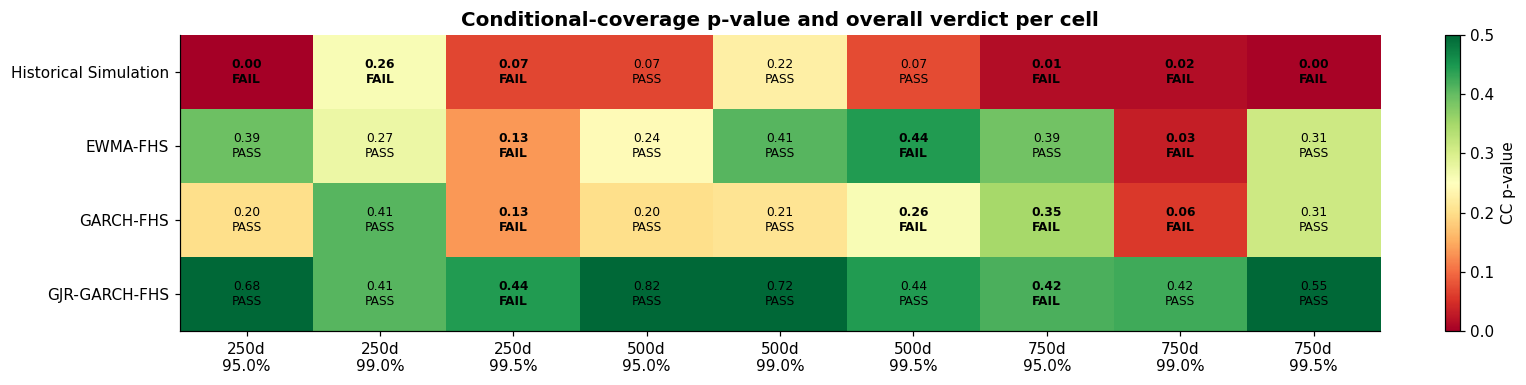

Pass count (of 9 cells): Historical Simulation 3, EWMA-FHS 6, GARCH-FHS 5, GJR-GARCH-FHS 7


In [11]:
mat = RES.pivot_table(index='Model', columns=['Window', 'Confidence'], values='CC p').loc[list(MODELS)]
ver = RES.pivot_table(index='Model', columns=['Window', 'Confidence'], values='Verdict', aggfunc='first').loc[list(MODELS)]
fig, ax = plt.subplots(figsize=(14, 3.6))
im = ax.imshow(mat.values, cmap='RdYlGn', vmin=0, vmax=0.5, aspect='auto')
ax.set_xticks(range(mat.shape[1]), [f'{w}d\n{c:.1%}' for w, c in mat.columns]); ax.set_yticks(range(len(mat)), [LABEL[m] for m in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f'{mat.values[i, j]:.2f}\n{ver.values[i, j]}', ha='center', va='center', fontsize=8,
                fontweight='bold' if ver.values[i, j] == 'FAIL' else 'normal')
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.02, label='CC p-value')
ax.set_title('Conditional-coverage p-value and overall verdict per cell')
plt.tight_layout(); plt.show()
print('Pass count (of 9 cells): ' + ', '.join(f'{LABEL[m]} {int((RES[RES.Model == m].Verdict == "PASS").sum())}' for m in MODELS))

## 5. Exception timelines at the headline (99%, 250-day)

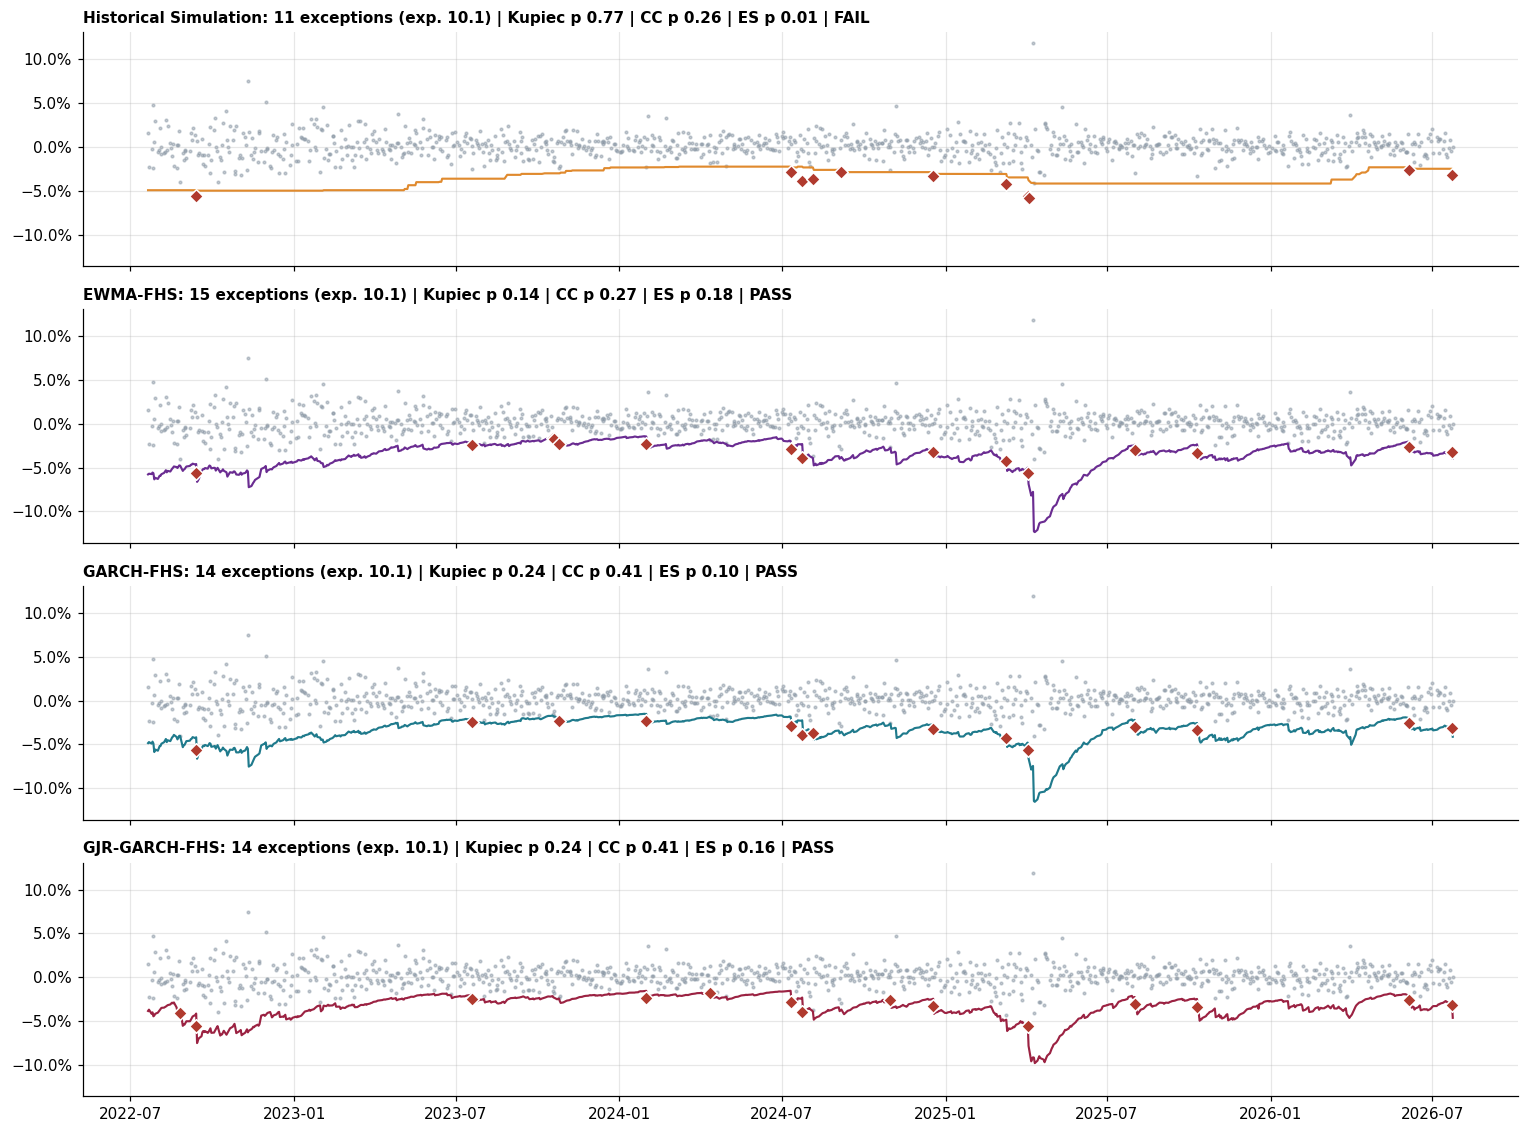

In [12]:
d = COMMON[HEADLINE_W]; r = returns.reindex(d)
fig, axes = plt.subplots(len(MODELS), 1, figsize=(14, 2.6 * len(MODELS)), sharex=True, sharey=True)
for ax, m in zip(axes, MODELS):
    v = MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].reindex(d)
    hit = r < -v
    ax.scatter(d, r, s=3, color=COLORS['muted'], alpha=0.5)
    ax.plot(-v, color=COLORS[m], lw=1.4)
    ax.scatter(d[hit], r[hit], s=40, marker='D', color=COLORS['loss'], edgecolor='white', zorder=5)
    row = RES[(RES.Model == m) & (RES.Window == HEADLINE_W) & (RES.Confidence == HEADLINE_CL)].iloc[0]
    ax.set_title(f'{LABEL[m]}: {row.Exceptions} exceptions (exp. {row.Expected:.1f}) | Kupiec p {row["Kupiec p"]:.2f} | '
                 f'CC p {row["CC p"]:.2f} | ES p {row["ES test p"]:.2f} | {row.Verdict}', fontsize=10, loc='left')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.show()

## 6. Clustering: do exceptions come in bunches?
π₀₁ is the chance of an exception after a quiet day, and π₁₁ the chance after an exception day. If π₁₁ is well above π₀₁, the model is slow to react after a loss. Short gaps between exceptions point the same way.

In [13]:
rows = []
for m in MODELS:
    v = MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].reindex(d)
    hit = (r < -v).astype(int).values
    _, p_ind, (n00, n01, n10, n11) = christoffersen(hit)
    pos = np.flatnonzero(hit); gaps = np.diff(pos)
    rows.append({'Model': LABEL[m], 'Exceptions': int(hit.sum()), 'π01 (after quiet)': n01 / max(n00 + n01, 1),
                 'π11 (after exception)': n11 / max(n10 + n11, 1), 'Back-to-back pairs': n11,
                 'Median gap (days)': np.median(gaps) if len(gaps) else np.nan, 'Shortest gap': gaps.min() if len(gaps) else np.nan,
                 'Max in any 20 days': int(pd.Series(hit).rolling(20).sum().max()), 'Indep. p': p_ind})
clu = pd.DataFrame(rows).set_index('Model')
clu.style.format({'π01 (after quiet)': '{:.2%}', 'π11 (after exception)': '{:.2%}', 'Median gap (days)': '{:.0f}', 'Shortest gap': '{:.0f}', 'Indep. p': '{:.3f}'})

,Exceptions,π01 (after quiet),π11 (after exception),Back-to-back pairs,Median gap (days),Shortest gap,Max in any 20 days,Indep. p
Model,,,,,,,,
Historical Simulation,11,1.01%,9.09%,1,28,1,3,0.105
EWMA-FHS,15,1.52%,0.00%,0,58,2,3,0.500
GARCH-FHS,14,1.41%,0.00%,0,66,8,3,0.529
GJR-GARCH-FHS,14,1.41%,0.00%,0,61,9,2,0.529


## 7. Expected Shortfall backtest in detail
On each exception day: actual loss ÷ forecast ES. If ES is right, the points scatter around 1.

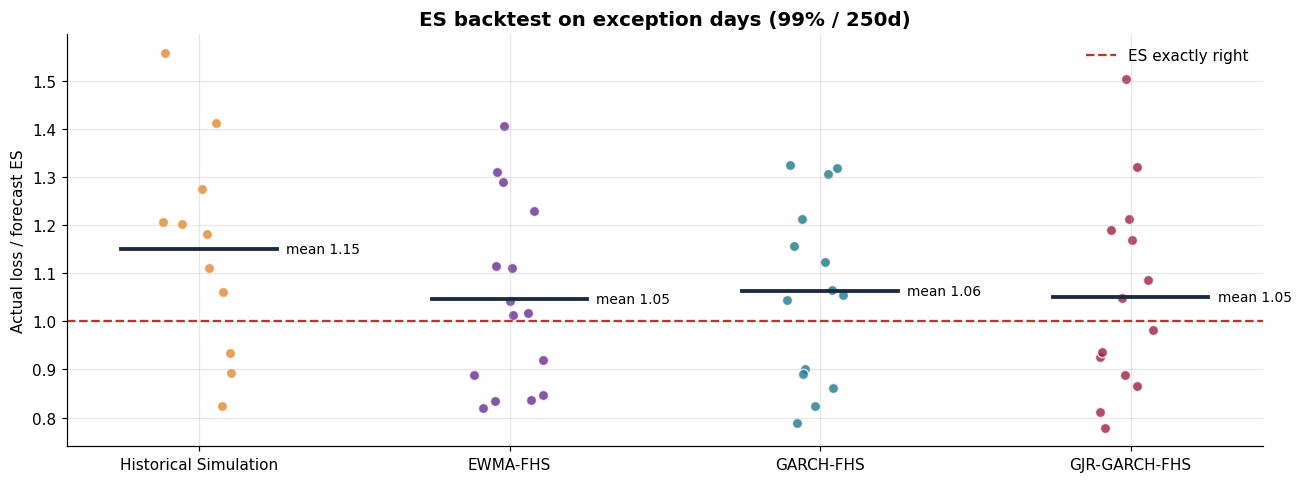

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, m in enumerate(MODELS):
    P = MODELS[m][(HEADLINE_W, HEADLINE_CL)]
    v, e = P['VaR'].reindex(d), P['ES'].reindex(d); hit = r < -v
    ratio = (-r[hit] / e[hit]).values
    ax.scatter(np.full(len(ratio), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(ratio)), ratio,
               color=COLORS[m], s=45, alpha=0.8, edgecolor='white')
    ax.plot([i - 0.25, i + 0.25], [ratio.mean()] * 2, color=COLORS['ink'], lw=2.5)
    ax.text(i + 0.28, ratio.mean(), f'mean {ratio.mean():.2f}', va='center', fontsize=9)
ax.axhline(1, color=COLORS['loss'], ls='--', label='ES exactly right')
ax.set_xticks(range(len(MODELS)), [LABEL[m] for m in MODELS]); ax.set_ylabel('Actual loss / forecast ES')
ax.legend(); ax.set_title(f'ES backtest on exception days ({HEADLINE_CL:.0%} / {HEADLINE_W}d)')
plt.tight_layout(); plt.show()

## 8. Basel traffic light over time and the capital it implies
Basel 2.5 charges capital of $\max\big(\text{VaR}^{10d}_{t},\;k_t\cdot\overline{\text{VaR}}^{10d}_{60}\big)$, with $\text{VaR}^{10d}=\sqrt{10}\,\text{VaR}^{1d}$ and the multiplier k set by the trailing 250-day exceptions (3.0 in green, up to 4.0 in red). A model that is too optimistic is **penalised through k**, so the cheapest model on paper isn't always the cheapest in practice. (Stressed VaR is excluded.)

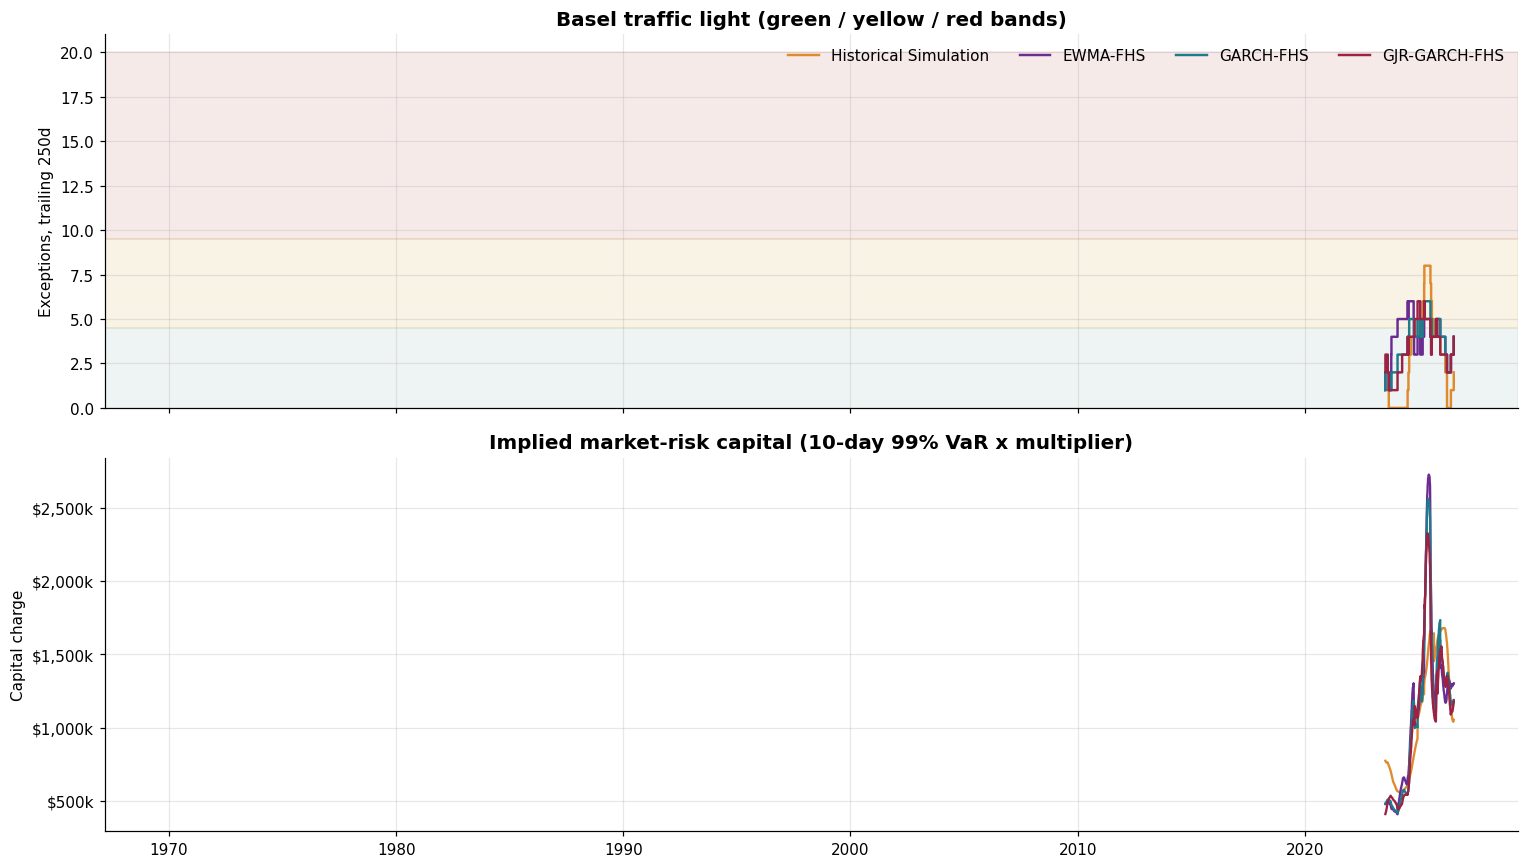

,Avg capital $,Avg capital % of NAV,Avg multiplier k,Days green,Days yellow,Days red,Capital today $
Historical Simulation,"$1,074,212",31.3%,3.13,76%,24%,0%,"$1,053,344"
EWMA-FHS,"$1,113,652",32.2%,3.17,61%,39%,0%,"$1,301,143"
GARCH-FHS,"$1,092,670",31.5%,3.13,70%,30%,0%,"$1,187,826"
GJR-GARCH-FHS,"$1,057,434",30.7%,3.10,75%,25%,0%,"$1,183,414"


In [15]:
CAP = {m: basel_capital(m) for m in MODELS}
cap_dates = COMMON[HEADLINE_W]
for m in MODELS: cap_dates = cap_dates.intersection(CAP[m]['Capital'].dropna().index)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
a0.axhspan(-0.5, 4.5, color='#2E7D68', alpha=0.08); a0.axhspan(4.5, 9.5, color='#C78B00', alpha=0.1); a0.axhspan(9.5, 20, color='#B03A2E', alpha=0.1)
for m in MODELS:
    a0.step(cap_dates, CAP[m]['x250'].reindex(cap_dates), where='post', color=COLORS[m], lw=1.6, label=LABEL[m])
    a1.plot(CAP[m]['Capital'].reindex(cap_dates), color=COLORS[m], lw=1.5, label=LABEL[m])
a0.set_ylim(0, max(12, a0.get_ylim()[1])); a0.set_ylabel('Exceptions, trailing 250d'); a0.legend(ncol=4)
a0.set_title('Basel traffic light (green / yellow / red bands)')
a1.yaxis.set_major_formatter(usd_fmt); a1.set_ylabel('Capital charge'); a1.set_title('Implied market-risk capital (10-day 99% VaR x multiplier)')
plt.tight_layout(); plt.show()

cap_tbl = pd.DataFrame({LABEL[m]: {
    'Avg capital $': CAP[m]['Capital'].reindex(cap_dates).mean(),
    'Avg capital % of NAV': (CAP[m]['Capital'] / start_value).reindex(cap_dates).mean(),
    'Avg multiplier k': CAP[m]['k'].reindex(cap_dates).mean(),
    'Days green': (CAP[m]['x250'].reindex(cap_dates) <= 4).mean(),
    'Days yellow': CAP[m]['x250'].reindex(cap_dates).between(5, 9).mean(),
    'Days red': (CAP[m]['x250'].reindex(cap_dates) >= 10).mean(),
    'Capital today $': CAP[m]['Capital'].iloc[-1]} for m in MODELS}).T
cap_tbl.style.format({'Avg capital $': '${:,.0f}', 'Avg capital % of NAV': '{:.1%}', 'Avg multiplier k': '{:.2f}',
                      'Days green': '{:.0%}', 'Days yellow': '{:.0%}', 'Days red': '{:.0%}', 'Capital today $': '${:,.0f}'})

## 9. Export for Task 9

In [16]:
RES.to_csv('Backtest_Results.csv', index=False)
pd.DataFrame({f'{m}_{k}': CAP[m][k] for m in MODELS for k in ['VaR10', 'k', 'x250', 'Capital']}).to_csv('Basel_Capital.csv')
cap_tbl.to_csv('Basel_Capital_Summary.csv')
exc = pd.DataFrame({'Return': r, **{f'{m}_VaR': MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].reindex(d) for m in MODELS},
                    **{f'{m}_Exception': (r < -MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].reindex(d)).astype(int) for m in MODELS}})
exc.to_csv('Exceptions_Headline.csv')
print('Saved: Backtest_Results.csv (36 rows), Basel_Capital.csv, Basel_Capital_Summary.csv, Exceptions_Headline.csv')

Saved: Backtest_Results.csv (36 rows), Basel_Capital.csv, Basel_Capital_Summary.csv, Exceptions_Headline.csv


## 10. Executive summary

In [17]:
h = RES[(RES.Window == HEADLINE_W) & (RES.Confidence == HEADLINE_CL)].set_index('Model')
lines = [f"**Headline (99% / 250d, {int(h.Days.iloc[0])} common days from {h.Start.iloc[0]:%b %Y}, {h.Expected.iloc[0]:.1f} exceptions expected)**"]
for m, row in h.iterrows():
    lines.append(f"- **{LABEL[m]}**: {row.Exceptions} exceptions; Kupiec p {row['Kupiec p']:.3f}, CC p {row['CC p']:.3f}, "
                 f"ES excess {row['ES excess']:+.0%} (p {row['ES test p']:.2f}); Basel **{row['Basel zone']}** now; "
                 f"avg capital {cap_tbl.loc[LABEL[m], 'Avg capital % of NAV']:.1%} of NAV -> **{row.Verdict}**")
passes = RES.groupby('Model')['Verdict'].apply(lambda s: (s == 'PASS').sum())
lines += ["", "**Across all 9 cells:** " + ", ".join(f"{LABEL[m]} passes {passes[m]}/9" for m in MODELS) + ".",
          f"**Red-zone time:** " + ", ".join(f"{k} {v:.0%}" for k, v in cap_tbl['Days red'].items()) + ".",
          "",
          f"**How to read this.** With {N_EVAL} days, Kupiec catches a 2x-too-optimistic 99% model only {reject_prob(N_EVAL, 0.99, 0.02):.0%} of the time, "
          "so several models passing doesn't mean they are equally good. **Task 9** separates them with proper scoring rules (quantile and FZ0 losses) "
          "and Diebold–Mariano significance tests, then recommends a production model."]
display(Markdown("\n".join(lines)))

**Headline (99% / 250d, 1006 common days from Jul 2022, 10.1 exceptions expected)**
- **Historical Simulation**: 11 exceptions; Kupiec p 0.769, CC p 0.258, ES excess +15% (p 0.01); Basel **GREEN** now; avg capital 31.3% of NAV -> **FAIL**
- **EWMA-FHS**: 15 exceptions; Kupiec p 0.145, CC p 0.275, ES excess +5% (p 0.18); Basel **GREEN** now; avg capital 32.2% of NAV -> **PASS**
- **GARCH-FHS**: 14 exceptions; Kupiec p 0.239, CC p 0.410, ES excess +6% (p 0.10); Basel **GREEN** now; avg capital 31.5% of NAV -> **PASS**
- **GJR-GARCH-FHS**: 14 exceptions; Kupiec p 0.239, CC p 0.410, ES excess +5% (p 0.16); Basel **GREEN** now; avg capital 30.7% of NAV -> **PASS**

**Across all 9 cells:** Historical Simulation passes 3/9, EWMA-FHS passes 6/9, GARCH-FHS passes 5/9, GJR-GARCH-FHS passes 7/9.
**Red-zone time:** Historical Simulation 0%, EWMA-FHS 0%, GARCH-FHS 0%, GJR-GARCH-FHS 0%.

**How to read this.** With 1006 days, Kupiec catches a 2x-too-optimistic 99% model only 79% of the time, so several models passing doesn't mean they are equally good. **Task 9** separates them with proper scoring rules (quantile and FZ0 losses) and Diebold–Mariano significance tests, then recommends a production model.

---
*Task 8 complete. Next: **Task 9, model comparison and selection.***

*Prepared by Arham Shah.*